# Research Collaborator Recommendation
Social Network Analysis AAT. This notebook executes the complete shared pipeline independently of Streamlit. Use Python 3.12 with requirements.txt.

Source: https://snap.stanford.edu/data/ca-GrQc.html. Nodes are dataset researcher IDs, edges are observed co-authorships. No names or interests are supplied.

In [1]:
from pathlib import Path
import sys
# Support launching from the project folder or outputs folder.
project = Path.cwd() if (Path.cwd() / 'analysis.py').exists() else Path.cwd().parent
sys.path.insert(0, str(project))
from analysis import *
from IPython.display import display, Image, HTML
summary = run()

{
  "full": {
    "nodes": 5242,
    "edges": 14484,
    "components": 355,
    "largest_component": 4158,
    "isolates": 1,
    "density": 0.0010544047057723853,
    "degree_min": 0,
    "degree_max": 81,
    "degree_mean": 5.526135062953071,
    "degree_median": 3.0,
    "average_clustering": 0.5296358110521362
  },
  "training": {
    "42": {
      "nodes": 5242,
      "edges": 11587,
      "components": 650,
      "largest_component": 3875,
      "isolates": 298,
      "density": 0.000843509205038983,
      "degree_min": 0,
      "degree_max": 64,
      "degree_mean": 4.42083174360931,
      "degree_median": 2.0,
      "average_clustering": 0.35692639194112163
    },
    "7": {
      "nodes": 5242,
      "edges": 11587,
      "components": 642,
      "largest_component": 3903,
      "isolates": 292,
      "density": 0.000843509205038983,
      "degree_min": 0,
      "degree_max": 68,
      "degree_mean": 4.42083174360931,
      "degree_median": 2.0,
      "average_clustering": 0.3

## Data preparation and graph model
The original gzip is preserved. Remove self-loops and duplicate unordered edges. Retain every node in the full simple undirected unweighted graph. Graph statistics below are computed, not copied from the source page.

In [2]:
g=load_graph()
display(pd.DataFrame([summary['full']]))
print('Raw rows:', summary['raw_rows'], 'Self-loop rows:',summary['self_loop_rows'], 'Duplicate/reverse rows:',summary['duplicate_or_reverse_rows'])
print('Original SHA256:',summary['sha256'])

,nodes,edges,components,largest_component,isolates,density,degree_min,degree_max,degree_mean,degree_median,average_clustering
0,5242,14484,355,4158,1,0.001054,0,81,5.526135,3.0,0.529636


Raw rows: 28980 Self-loop rows: 12 Duplicate/reverse rows: 14484
Original SHA256: a254442cdf5d684712578b630c2e0d7543518ab154ef2341cabb607572ce7230


## Reproducible evaluation
Primary seed 42. Sort unique edges, shuffle with Python random.Random, retain floor(0.8 M) edges for training and hold out the remainder. Add all original nodes before adding training edges. Negatives are distinct full-graph nonedges with no self-pairs, sampled 1:1 with positives. All methods use exactly the same evaluation pairs. Test edges enter labels only, never scoring or tuning.

In [3]:
display(pd.DataFrame(summary['training']).T)
train=pd.read_csv(DATA/'train_edges.csv')
test=pd.read_csv(DATA/'test_edges.csv')
neg=pd.read_csv(DATA/'negative_pairs.csv')
assert set(map(tuple,train.values)).isdisjoint(map(tuple,test.values))
assert all(not g.has_edge(int(u),int(v)) for u,v in neg.values)
print('Primary train/test/negative counts:',len(train),len(test),len(neg))

,nodes,edges,components,largest_component,isolates,density,degree_min,degree_max,degree_mean,degree_median,average_clustering
42,5242.0,11587.0,650.0,3875.0,298.0,0.000844,0.0,64.0,4.420832,2.0,0.356926
7,5242.0,11587.0,642.0,3903.0,292.0,0.000844,0.0,68.0,4.420832,2.0,0.356449
21,5242.0,11587.0,648.0,3882.0,307.0,0.000844,0.0,66.0,4.420832,2.0,0.361951
84,5242.0,11587.0,631.0,3879.0,268.0,0.000844,0.0,69.0,4.420832,2.0,0.355331


Primary train/test/negative counts: 11587 2897 2897


## Four structural scores
Let $N(u)$ be the neighbors of researcher $u$, and $d(u)=|N(u)|$. Scores are similarities, not probabilities.

### Common Neighbors
$$|N(u) \cap N(v)|$$
Counts shared collaborators.

### Jaccard
$$\frac{|N(u)\cap N(v)|}{|N(u)\cup N(v)|}$$
Divides shared collaborators by the size of the combined collaborator set.

### Adamic-Adar
$$\sum_{w\in N(u)\cap N(v)}\frac{1}{\ln d(w)}$$
Gives more weight to shared collaborators who have fewer connections.

### Preferential Attachment
$$d(u)d(v)$$
Multiplies the two researchers' degrees, favoring well-connected researchers.

In [4]:
# Every evaluation pair is checked against NetworkX during run().
t=nx.Graph(); t.add_nodes_from(g); t.add_edges_from(train.values.tolist())
u,v=map(int,test.iloc[0])
print('Example held-out pair:',u,v,'training-only scores:',dict(zip(METHODS,scores(t,u,v))))

Example held-out pair: 22 15793 training-only scores: {'Common Neighbors': 3, 'Jaccard': 0.6, 'Adamic-Adar': 3.263173494142638, 'Preferential Attachment': 16}


## Metrics and tie handling
ROC-AUC compares positive/negative ordering, with half credit for tied scores. Precision@K = true positives in the first K / K. Recall@K = true positives in the first K / all held-out positives. F1@K = 2PR/(P+R), or zero when P+R is zero. Recall and F1 are at K. Sort by descending score, then ascending unordered researcher IDs. Precision on this balanced sampled set differs from precision over all missing links.

,seed,method,ROC_AUC,Precision@10,Recall@10,F1@10,Precision@20,Recall@20,F1@20
0,42,Common Neighbors,0.888701,1.0,0.003452,0.00688,1.0,0.006904,0.013713
1,42,Jaccard,0.888816,1.0,0.003452,0.00688,1.0,0.006904,0.013713
2,42,Adamic-Adar,0.888945,1.0,0.003452,0.00688,1.0,0.006904,0.013713
3,42,Preferential Attachment,0.735022,1.0,0.003452,0.00688,1.0,0.006904,0.013713


Strongest by primary ROC-AUC: Adamic-Adar


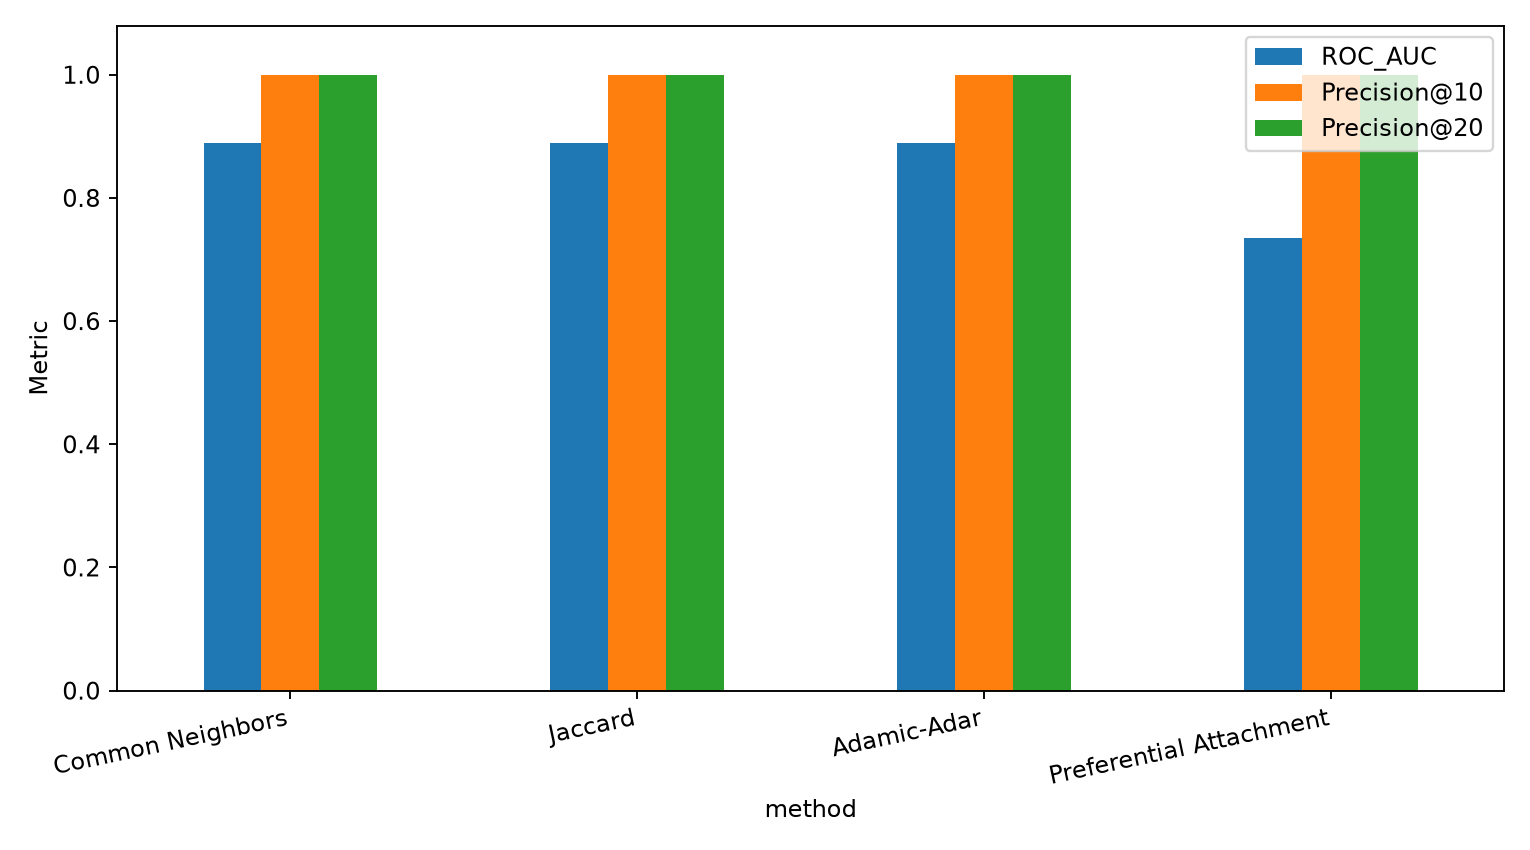

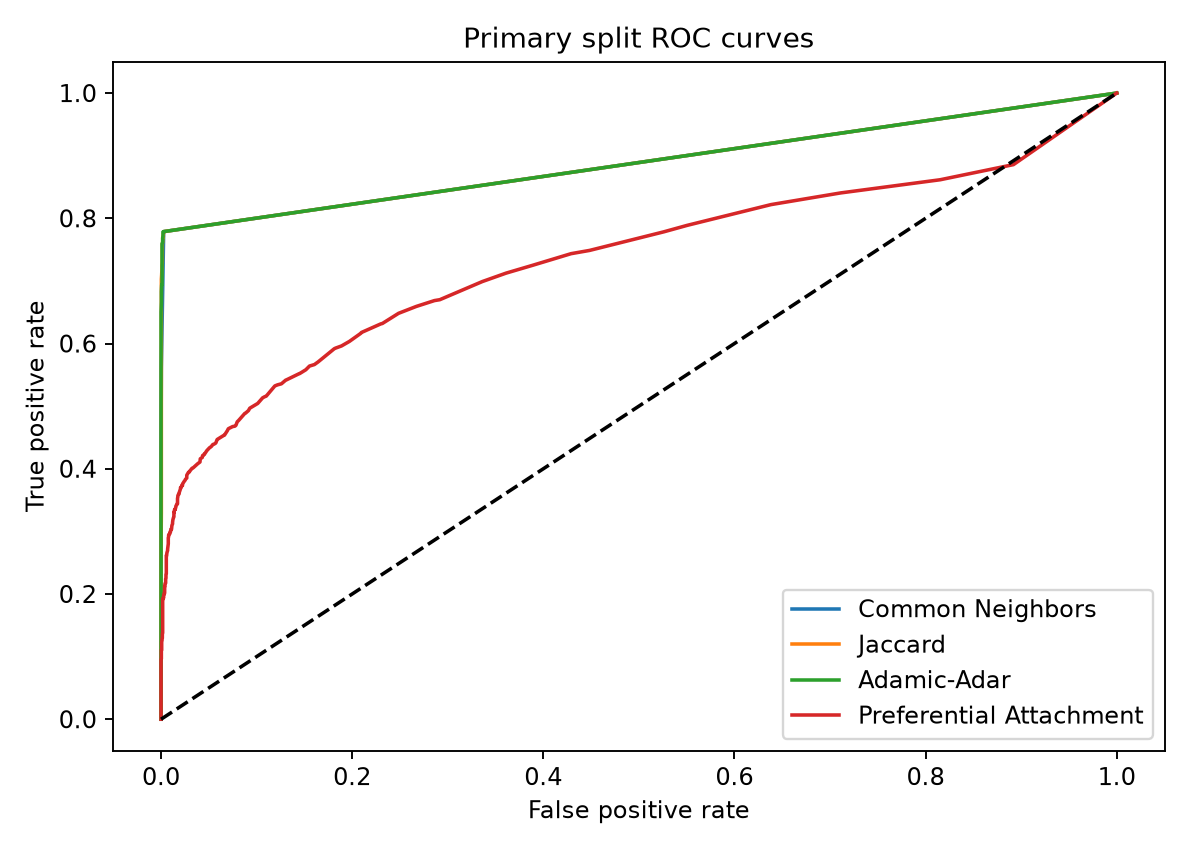

In [5]:
metrics=pd.read_csv(OUT/'evaluation.csv'); display(metrics)
print('Strongest by primary ROC-AUC:', summary['best_method'])
display(Image(filename=str(FIG/'model_comparison.png')))
display(Image(filename=str(FIG/'roc_curves.png')))

## Split sensitivity
Seeds 7, 21 and 84 repeat the complete split and negative sampling. The primary split remains seed 42. This describes sensitivity rather than an independent validation of the selected method.

In [6]:
sensitivity=pd.read_csv(OUT/'sensitivity.csv'); display(sensitivity)
display(sensitivity.groupby('method')['ROC_AUC'].agg(['mean','std','min','max']))

,seed,method,ROC_AUC,Precision@10,Recall@10,F1@10,Precision@20,Recall@20,F1@20
0,42,Common Neighbors,0.888701,1.0,0.003452,0.00688,1.0,0.006904,0.013713
1,42,Jaccard,0.888816,1.0,0.003452,0.00688,1.0,0.006904,0.013713
2,42,Adamic-Adar,0.888945,1.0,0.003452,0.00688,1.0,0.006904,0.013713
3,42,Preferential Attachment,0.735022,1.0,0.003452,0.00688,1.0,0.006904,0.013713
4,7,Common Neighbors,0.902587,1.0,0.003452,0.00688,1.0,0.006904,0.013713
5,7,Jaccard,0.902548,1.0,0.003452,0.00688,1.0,0.006904,0.013713
6,7,Adamic-Adar,0.902723,1.0,0.003452,0.00688,1.0,0.006904,0.013713
7,7,Preferential Attachment,0.734948,1.0,0.003452,0.00688,1.0,0.006904,0.013713
8,21,Common Neighbors,0.900411,1.0,0.003452,0.00688,1.0,0.006904,0.013713
9,21,Jaccard,0.900459,1.0,0.003452,0.00688,1.0,0.006904,0.013713


,mean,std,min,max
method,,,,
Adamic-Adar,0.897719,0.006106,0.888945,0.902723
Common Neighbors,0.897470,0.006116,0.888701,0.902587
Jaccard,0.897565,0.006069,0.888816,0.902548
Preferential Attachment,0.738970,0.004683,0.734948,0.744018


## Full-network recommendations
After evaluation, score the complete cleaned observed network. Examine every unordered nonedge exactly, streaming candidates through four heaps of size 20. No filtering is used. Exclude self-pairs and existing links. Each method has its own deterministic ranking. These are structural possibilities.

In [7]:
recommendations=pd.read_csv(OUT/'recommendations_top20.csv')
print('Exact candidate nonedges:',summary['candidate_non_edges'])
for method in METHODS:
    print(method,'top 20 (first 10 are the top 10)')
    display(recommendations[recommendations.method==method])
assert all(not g.has_edge(int(u),int(v)) and u!=v for u,v in recommendations[['researcher_1','researcher_2']].values)

Exact candidate nonedges: 13722177
Common Neighbors top 20 (first 10 are the top 10)


,researcher_1,researcher_2,method,rank,score,shared_collaborators
0,45,46,Common Neighbors,1,42.0,42
1,4511,4513,Common Neighbors,2,42.0,42
2,4511,22691,Common Neighbors,3,42.0,42
3,46,4513,Common Neighbors,4,41.0,41
4,46,22691,Common Neighbors,5,41.0,41
5,5210,7444,Common Neighbors,6,25.0,25
6,7444,8727,Common Neighbors,7,25.0,25
7,7444,9869,Common Neighbors,8,25.0,25
8,7444,12710,Common Neighbors,9,25.0,25
9,7444,15245,Common Neighbors,10,25.0,25


Jaccard top 20 (first 10 are the top 10)


,researcher_1,researcher_2,method,rank,score,shared_collaborators
20,29,16751,Jaccard,1,1.0,1
21,85,5413,Jaccard,2,1.0,1
22,114,2348,Jaccard,3,1.0,1
23,114,6631,Jaccard,4,1.0,1
24,123,23240,Jaccard,5,1.0,1
25,195,19168,Jaccard,6,1.0,3
26,232,1075,Jaccard,7,1.0,1
27,232,13481,Jaccard,8,1.0,1
28,232,16742,Jaccard,9,1.0,1
29,252,15418,Jaccard,10,1.0,1


Adamic-Adar top 20 (first 10 are the top 10)


,researcher_1,researcher_2,method,rank,score,shared_collaborators
40,45,46,Adamic-Adar,1,10.597803,42
41,4511,4513,Adamic-Adar,2,10.592055,42
42,4511,22691,Adamic-Adar,3,10.592055,42
43,46,4513,Adamic-Adar,4,10.335106,41
44,46,22691,Adamic-Adar,5,10.335106,41
45,5210,7444,Adamic-Adar,6,6.699083,25
46,7444,8727,Adamic-Adar,7,6.699083,25
47,7444,9869,Adamic-Adar,8,6.699083,25
48,7444,12710,Adamic-Adar,9,6.699083,25
49,7444,15245,Adamic-Adar,10,6.699083,25


Preferential Attachment top 20 (first 10 are the top 10)


,researcher_1,researcher_2,method,rank,score,shared_collaborators
60,15244,21012,Preferential Attachment,1,4779.0,0
61,15244,21281,Preferential Attachment,2,4661.0,0
62,12365,15244,Preferential Attachment,3,4543.0,0
63,15244,22691,Preferential Attachment,4,4543.0,0
64,6610,15244,Preferential Attachment,5,4012.0,0
65,9785,15244,Preferential Attachment,6,4012.0,0
66,6512,21012,Preferential Attachment,7,3969.0,0
67,15244,21508,Preferential Attachment,8,3953.0,0
68,15244,17655,Preferential Attachment,9,3894.0,0
69,6512,21281,Preferential Attachment,10,3871.0,0


In [8]:
for row in recommendations[recommendations.method==summary['best_method']].head(3).itertuples():
    common=sorted(nx.common_neighbors(g,row.researcher_1,row.researcher_2))
    print(f'{row.researcher_1} + {row.researcher_2}: score={row.score:.6g}; degrees={g.degree(row.researcher_1)}, {g.degree(row.researcher_2)}; shared IDs={common}')

45 + 46: score=10.5978; degrees=49, 42; shared IDs=[570, 773, 1653, 2212, 2741, 2952, 3372, 4164, 4511, 6179, 6610, 6830, 7956, 8879, 9785, 11241, 11472, 12365, 12496, 12781, 12851, 14540, 14807, 15003, 15659, 17655, 17692, 18894, 19423, 19961, 20108, 20562, 20635, 21012, 21281, 21508, 21847, 22887, 23293, 24955, 25346, 25758]
4511 + 4513: score=10.5921; degrees=45, 43; shared IDs=[45, 570, 773, 1653, 2212, 2741, 2952, 3372, 4164, 6179, 6610, 6830, 7956, 8879, 9785, 11241, 11472, 12365, 12496, 12781, 12851, 14540, 14807, 15003, 15659, 17655, 17692, 18894, 19423, 19961, 20108, 20562, 20635, 21012, 21281, 21508, 21847, 22887, 23293, 24955, 25346, 25758]
4511 + 22691: score=10.5921; degrees=45, 77; shared IDs=[45, 570, 773, 1653, 2212, 2741, 2952, 3372, 4164, 6179, 6610, 6830, 7956, 8879, 9785, 11241, 11472, 12365, 12496, 12781, 12851, 14540, 14807, 15003, 15659, 17655, 17692, 18894, 19423, 19961, 20108, 20562, 20635, 21012, 21281, 21508, 21847, 22887, 23293, 24955, 25346, 25758]


## Visualizations
The degree chart uses the full network. The overview uses a deterministic breadth-first subset of at most 35 nodes rooted at the lowest researcher ID with degree 3 in the largest component, with degree then ID ordering. The recommendation view shows three top pairs from the strongest primary-AUC method and up to 10 shared collaborators per pair, with induced observed edges. Gray lines are observed, orange dashed lines are predictions. Full-network analysis remains unchanged.

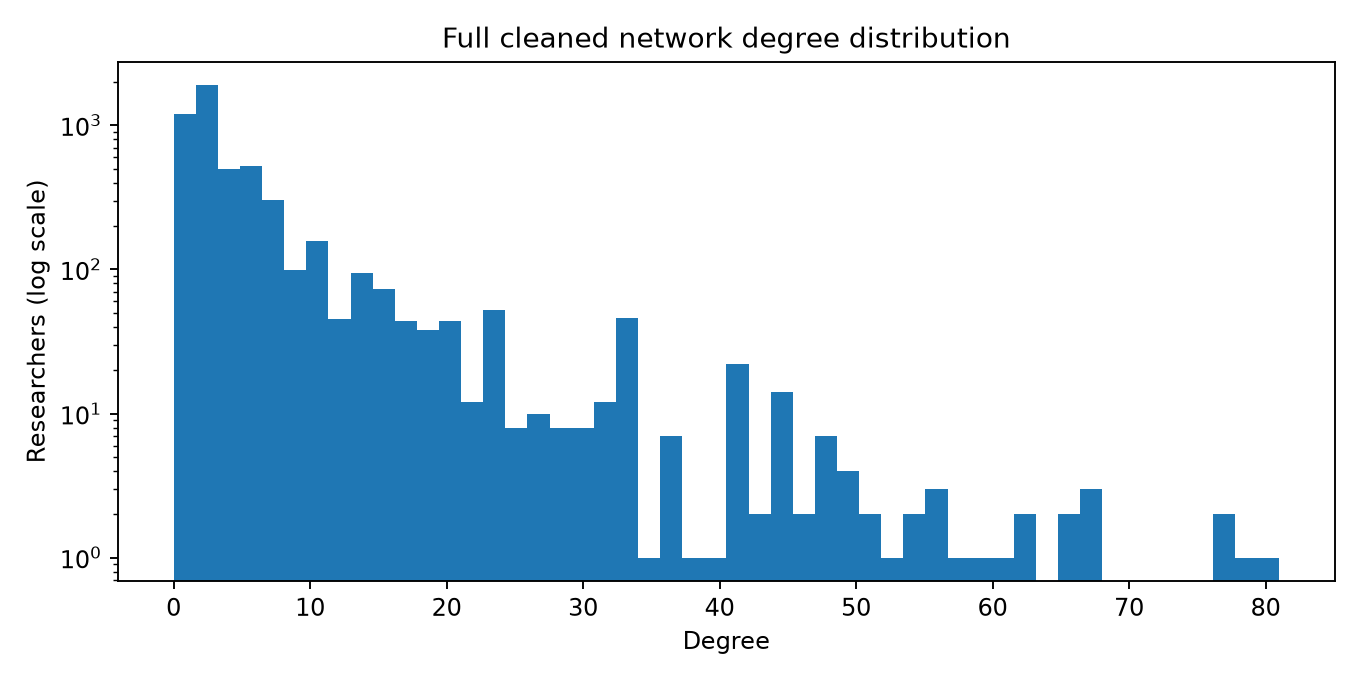

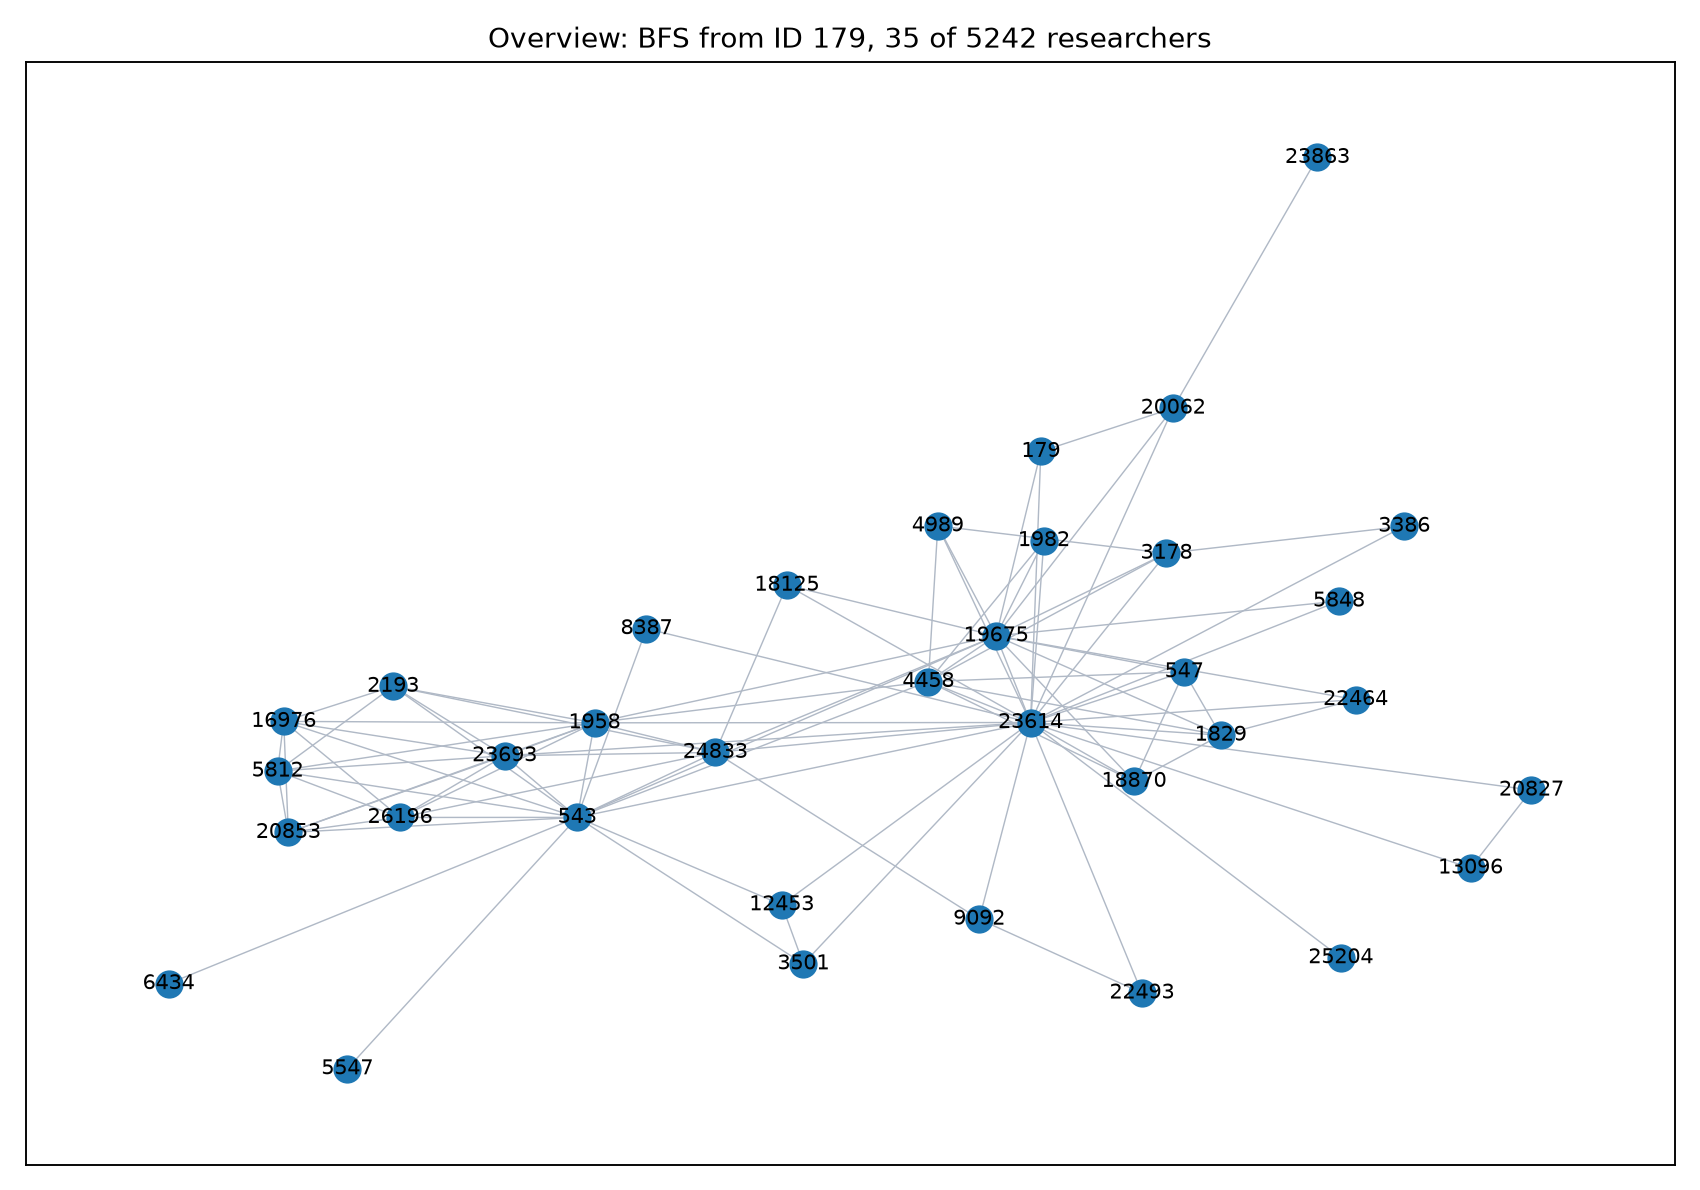

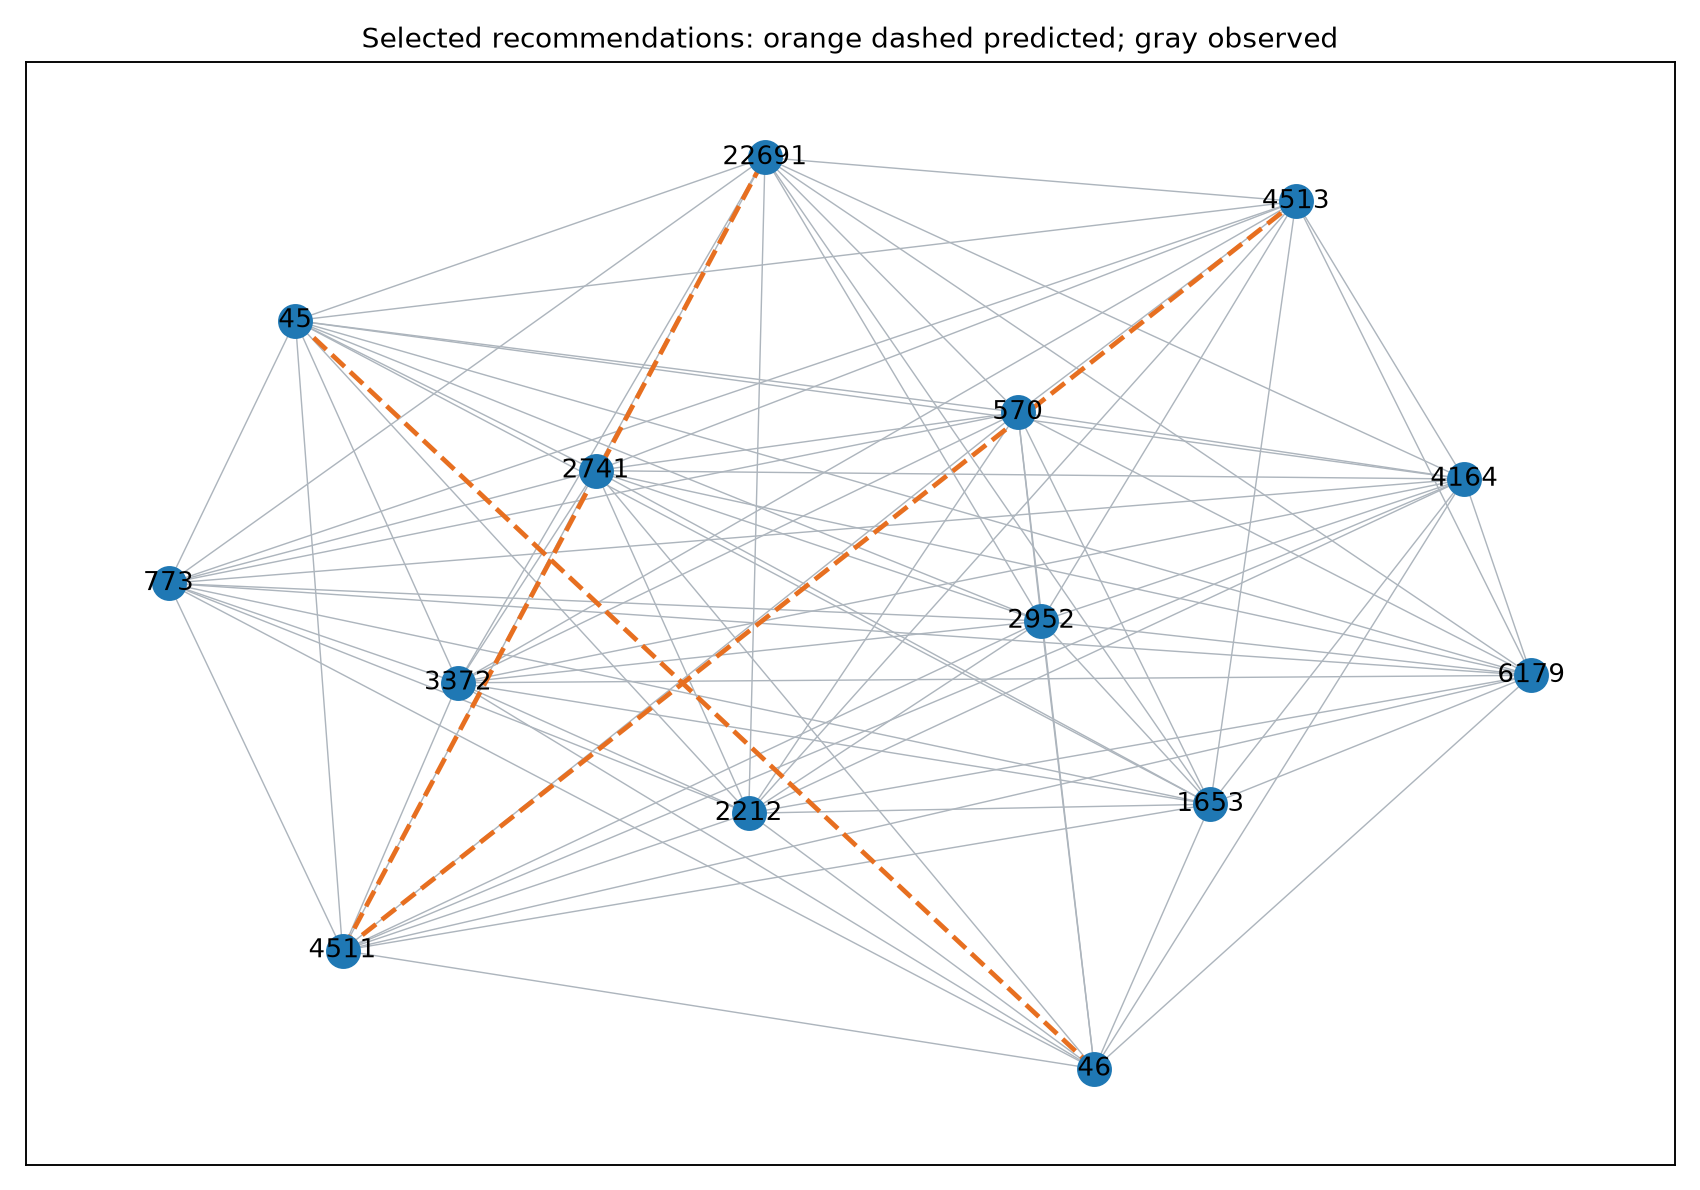

In [9]:
for name in ['degree_distribution','network_overview','recommended_links']:
    display(Image(filename=str(FIG/(name+'.png'))))
display(HTML((OUT/'network.html').read_text(encoding='utf-8')))

## Application
From the project directory: `python -m streamlit run app.py`. The app imports this same analysis module and reads the generated CSVs. It caches graph loading and researcher results. Explorer views are bounded. See README.md for setup and the demo sequence.

## Limitations and conclusion
IDs have no supplied names, affiliations or interests. Recommendations are structural possibilities, not confirmed collaborations or assessments of research compatibility. Sampled nonedges are assumed negatives. A random edge split tests recovery of missing observed links, not future collaboration prediction. Balanced sampled precision differs from precision across all missing links. The best method is selected on these same test results, without independent validation.

Cytoscape was unavailable on PATH. Python figures and a self-contained PyVis HTML supply equivalent views. No Cytoscape render was produced. Dataset import instructions are in dataset/README.md.

References: Leskovec, Kleinberg and Faloutsos (2007), Graph Evolution: Densification and Shrinking Diameters, ACM TKDD 1(1); https://snap.stanford.edu/data/ca-GrQc.html; https://networkx.org/documentation/stable/reference/algorithms/link_prediction.html; Liben-Nowell and Kleinberg (2007), The link-prediction problem for social networks, JASIST 58(7).